In [55]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

In [56]:
df = pd.read_csv('/Users/sachinchoudhary/Developer/ML/data/train.csv', usecols=['Survived','Age','Fare'])
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Age       714 non-null    float64
 2   Fare      891 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 21.0 KB


In [58]:
df.isnull().mean()*100

Survived     0.00000
Age         19.86532
Fare         0.00000
dtype: float64

In [59]:
X_train, X_test, y_train, y_test = train_test_split(df.drop(columns=['Survived']),df['Survived'],test_size=0.2)

In [60]:
X_train['Age_imputed'] = X_train['Age']
X_test['Age_imputed'] = X_test['Age']

In [61]:
X_train['Age_imputed'][X_train['Age_imputed'].isnull()] = X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values
X_test['Age_imputed'][X_test['Age_imputed'].isnull()] = X_test['Age'].dropna().sample(X_test['Age'].isnull().sum()).values

/var/folders/lh/42glnkrn40x_dxrvypysh9w00000gn/T/ipykernel_8597/1252176479.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  X_train['Age_imputed'][X_train['Age_imputed'].isnull()] = X_train['Age'].dropna().sample(X_train['Age'].isnull().s

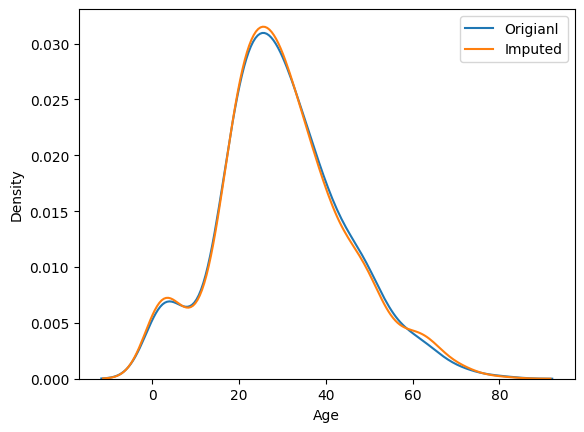

In [62]:
sns.kdeplot(X_train['Age'], label='Origianl')
sns.kdeplot(X_train['Age_imputed'], label='Imputed')

plt.legend()
plt.show()

In [63]:
print('Origianl variable variance ->',X_train['Age'].var())
print('Variance after imputed ->',X_train['Age_imputed'].var())

Origianl variable variance -> 206.09153794231773
Variance after imputed -> 211.98803860364416


In [64]:
X_train[['Fare','Age','Age_imputed']].cov()

,Fare,Age,Age_imputed
Fare,2245.071827,74.187644,59.735587
Age,74.187644,206.091538,206.091538
Age_imputed,59.735587,206.091538,211.988039


<Axes: >

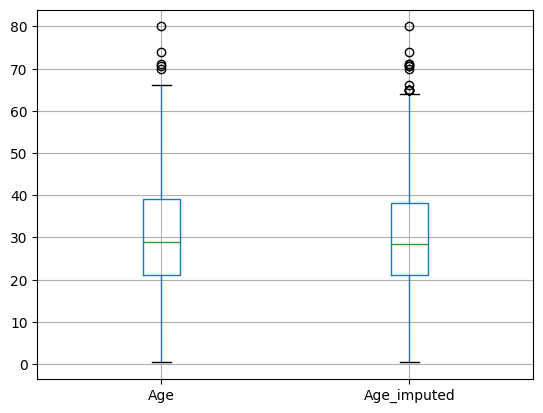

In [65]:
X_train[['Age','Age_imputed']].boxplot()

In [66]:
# sample_value = X_train['Age'].dropna().sample(1,random_state=int(X_train['Fare']))

# Categorical Data

In [67]:
data = pd.read_csv('/Users/sachinchoudhary/Developer/ML/data/Housing.csv', usecols=['GarageQual','FireplaceQu','SalePrice'])
data.sample(5)

,FireplaceQu,GarageQual,SalePrice
1137,NaN,NaN,94000
768,Gd,TA,216837
1160,TA,TA,146000
561,TA,TA,170000
977,NaN,TA,199900


In [68]:
data.isnull().mean()*100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

In [69]:
X_train, X_test, y_train, y_test = train_test_split(data,data['SalePrice'],test_size=0.2,random_state=2)

In [70]:
X_train['GarageQual_imputed'] = X_train['GarageQual']
X_test['GarageQual_imputed'] = X_test['GarageQual']

X_train['FireplaceQu_imited'] = X_train['FireplaceQu']
X_test['FireplaceQu_imited'] = X_test['FireplaceQu']

In [88]:
X_train['GarageQual_imputed'][X_train['GarageQual_imputed'].isnull()] = X_train['GarageQual'].dropna().sample(X_train['GarageQual'].isnull().sum()).values
X_train['FireplaceQu_imited'][X_train['FireplaceQu_imited'].isnull()] = X_train['FireplaceQu'].dropna().sample(X_train['FireplaceQu'].isnull().sum()).values

X_test['FireplaceQu_imited'][X_test['FireplaceQu_imited'].isnull()] = X_test['FireplaceQu'].dropna().sample(X_test['FireplaceQu'].isnull().sum()).values
X_test['GarageQual_imputed'][X_test['GarageQual_imputed'].isnull()] = X_test['GarageQual'].dropna().sample(X_test['GarageQual'].isnull().sum()).values

/var/folders/lh/42glnkrn40x_dxrvypysh9w00000gn/T/ipykernel_8597/1198406516.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  X_train['GarageQual_imputed'][X_train['GarageQual_imputed'].isnull()] = X_train['GarageQual'].dropna().sample(X_tr

In [89]:
X_test['GarageQual_imputed'].isnull().sum()

np.int64(0)

In [72]:
temp = pd.concat([
    X_train['GarageQual'].value_counts()/len(X_train['GarageQual'].dropna()),
    X_train['GarageQual_imputed'].value_counts()/len(X_train)
], axis=1)
temp.columns = ['original','imputed']


In [73]:
temp

,original,imputed
TA,0.951043,0.952055
Fa,0.037171,0.036815
Gd,0.009973,0.009418
Po,0.000907,0.000856
Ex,0.000907,0.000856


In [74]:
temp1 = pd.concat([
    X_train['FireplaceQu'].value_counts()/len(X_train['FireplaceQu'].dropna()),
    X_train['FireplaceQu_imited'].value_counts()/len(X_train)
], axis=1)
temp1.columns = ['original','imputed']
temp1

,original,imputed
Gd,0.494272,0.493151
TA,0.412439,0.415240
Fa,0.040917,0.039384
Po,0.027823,0.026541
Ex,0.024550,0.025685


In [85]:
for category in X_train['FireplaceQu'].dropna().unique():
    sns.displot(X_train[X_train['FireplaceQu'] == category][X_train['SalePrice']], hist=False,label=category)

plt.show()

KeyError: "None of [Index([175500, 132500, 147000, 257000, 131000, 160000, 185900, 160000, 127500,\n       117000,\n       ...\n       181000, 140000, 190000, 156000, 157000, 167000, 158500, 155000, 446261,\n       125000],\n      dtype='int64', length=1168)] are in the [columns]"

In [86]:
for category in X_train['FireplaceQu_imited'].dropna().unique():
    sns.displot(X_train[X_train['FireplaceQu_imited'] == category][X_train['SalePrice']], hist=False,label=category)

plt.show()

KeyError: "None of [Index([175500, 132500, 147000, 257000, 131000, 160000, 185900, 160000, 127500,\n       117000,\n       ...\n       181000, 140000, 190000, 156000, 157000, 167000, 158500, 155000, 446261,\n       125000],\n      dtype='int64', length=1168)] are in the [columns]"